In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../datasets/diabetes_012_health_indicators_BRFSS2015.csv")

print(df.shape)

df.head()

(253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
print("="*70)
print("DATASET INFORMATION")
print("="*70)

df.info()

print("\n")

print(df.describe())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non

In [4]:
print(df.isnull().sum())

Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64


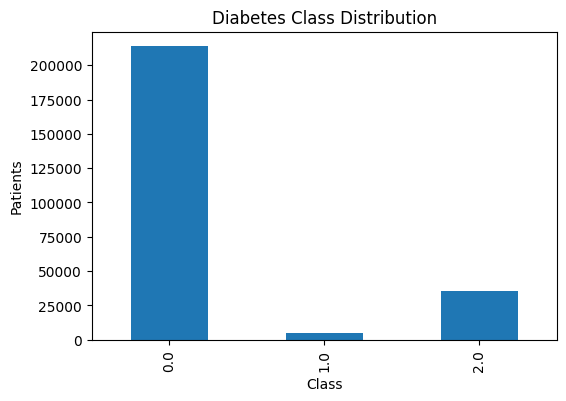

In [5]:
print(df["Diabetes_012"].value_counts())

plt.figure(figsize=(6,4))

df["Diabetes_012"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Diabetes Class Distribution")

plt.xlabel("Class")

plt.ylabel("Patients")

plt.show()

In [6]:
selected_features = [

    "HighBP",

    "HighChol",

    "BMI",

    "Smoker",

    "Stroke",

    "HeartDiseaseorAttack",

    "PhysActivity",

    "Fruits",

    "Veggies",

    "HvyAlcoholConsump",

    "GenHlth",

    "PhysHlth",

    "DiffWalk",

    "Sex",

    "Age",

    "Diabetes_012"

]

df = df[selected_features]

df.head()

,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,PhysHlth,DiffWalk,Sex,Age,Diabetes_012
0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,5.0,15.0,1.0,0.0,9.0,0.0
1,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,7.0,0.0
2,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5.0,30.0,1.0,0.0,9.0,0.0
3,1.0,0.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0,0.0,11.0,0.0
4,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0,0.0,11.0,0.0


In [7]:
df.rename(
    columns={
        "Diabetes_012":"target"
    },
    inplace=True
)

df.head()

,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,PhysHlth,DiffWalk,Sex,Age,target
0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,5.0,15.0,1.0,0.0,9.0,0.0
1,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,7.0,0.0
2,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5.0,30.0,1.0,0.0,9.0,0.0
3,1.0,0.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0,0.0,11.0,0.0
4,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0,0.0,11.0,0.0


In [8]:
print(df["target"].value_counts())

target
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64


In [9]:
X = df.drop("target", axis=1)

y = df["target"]

print(X.shape)

print(y.shape)

(253680, 15)
(253680,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

print(X_train.shape)

print(X_test.shape)

(202944, 15)
(50736, 15)


In [11]:
from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.svm import SVC

from xgboost import XGBClassifier

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    classification_report

)

In [12]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42
    )

}

In [13]:
results = []

trained_models = {}

for name, model in models.items():

    print("="*70)

    print(f"Training {name}")

    print("="*70)

    model.fit(X_train, y_train)

    trained_models[name] = model

    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)

    precision = precision_score(

        y_test,

        pred,

        average="macro",

        zero_division=0

    )

    recall = recall_score(

        y_test,

        pred,

        average="macro",

        zero_division=0

    )

    f1 = f1_score(

        y_test,

        pred,

        average="macro",

        zero_division=0

    )

    results.append({

        "Model": name,

        "Accuracy": round(accuracy,4),

        "Precision": round(precision,4),

        "Recall": round(recall,4),

        "F1 Score": round(f1,4)

    })

    print(classification_report(y_test,pred))

Training Logistic Regression


c:\Users\varad khodave\healthcare-platform\ml\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\varad khodave\healthcare-platform\ml\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\varad khodave\healthcare-platform\ml\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

              precision    recall  f1-score   support

         0.0       0.86      0.98      0.91     42741
         1.0       0.00      0.00      0.00       926
         2.0       0.52      0.17      0.25      7069

    accuracy                           0.85     50736
   macro avg       0.46      0.38      0.39     50736
weighted avg       0.80      0.85      0.81     50736

Training Decision Tree
              precision    recall  f1-score   support

         0.0       0.87      0.89      0.88     42741
         1.0       0.03      0.03      0.03       926
         2.0       0.32      0.29      0.30      7069

    accuracy                           0.79     50736
   macro avg       0.41      0.40      0.41     50736
weighted avg       0.78      0.79      0.79     50736

Training Random Forest
              precision    recall  f1-score   support

         0.0       0.87      0.95      0.91     42741
         1.0       0.03      0.00      0.01       926
         2.0       0.42      

In [15]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(

    by="Accuracy",

    ascending=False

)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
3,XGBoost,0.8479,0.4681,0.3847,0.3943
0,Logistic Regression,0.8454,0.4590,0.3816,0.3899
2,Random Forest,0.8310,0.4394,0.3948,0.4044
1,Decision Tree,0.7896,0.4087,0.4022,0.4051


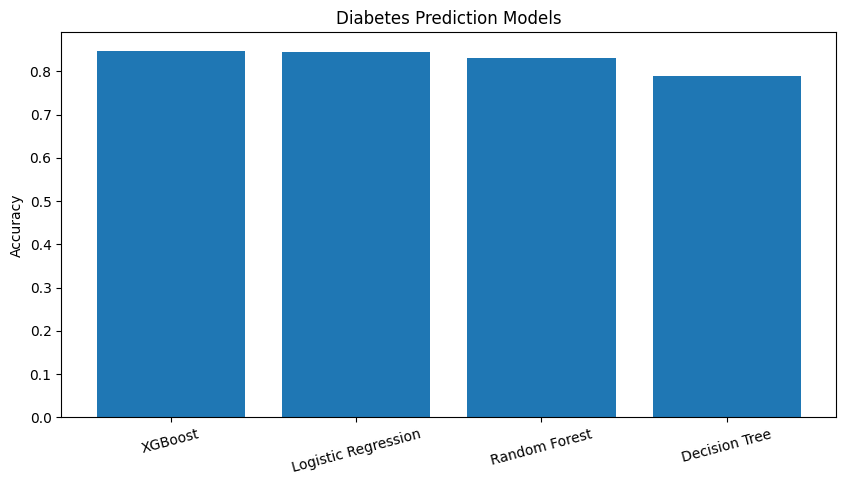

In [16]:
plt.figure(figsize=(10,5))

plt.bar(

    results_df["Model"],

    results_df["Accuracy"]

)

plt.title("Diabetes Prediction Models")

plt.ylabel("Accuracy")

plt.xticks(rotation=15)

plt.show()

In [17]:
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)

best_model = trained_models[best_model_name]

Best Model: XGBoost


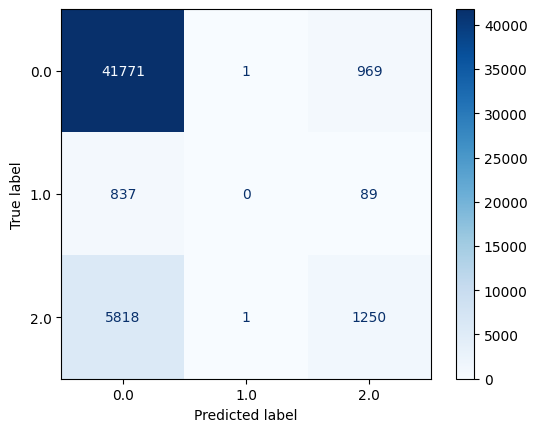

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

pred = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(

    y_test,

    pred,

    cmap="Blues"

)

plt.show()

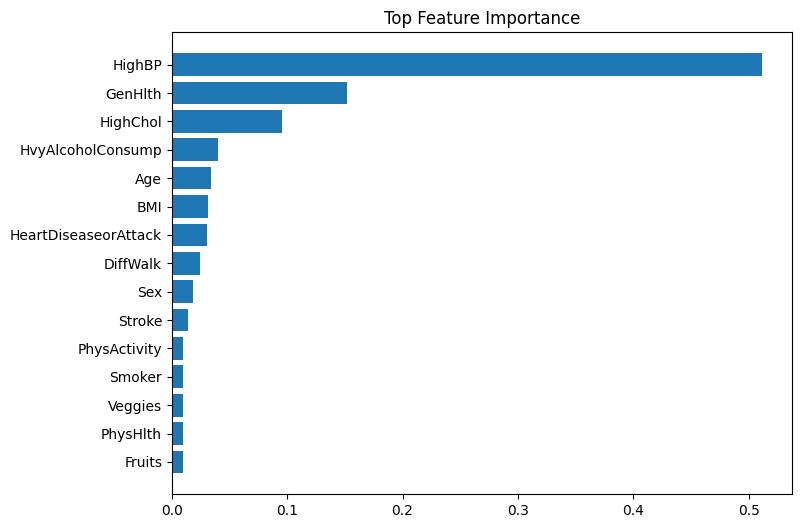

,Feature,Importance
0,HighBP,0.511868
10,GenHlth,0.151848
1,HighChol,0.095253
9,HvyAlcoholConsump,0.039668
14,Age,0.034213
2,BMI,0.031600
5,HeartDiseaseorAttack,0.030196
12,DiffWalk,0.024195
13,Sex,0.018038
4,Stroke,0.013870


In [19]:
if hasattr(best_model, "feature_importances_"):

    importance = pd.DataFrame({

        "Feature": X.columns,

        "Importance": best_model.feature_importances_

    })

    importance = importance.sort_values(

        by="Importance",

        ascending=False

    )

    plt.figure(figsize=(8,6))

    plt.barh(

        importance["Feature"][:15],

        importance["Importance"][:15]

    )

    plt.title("Top Feature Importance")

    plt.gca().invert_yaxis()

    plt.show()

    display(importance.head(15))

In [20]:
import joblib

joblib.dump(

    best_model,

    "../saved_models/diabetes_model.pkl"

)

joblib.dump(

    list(X.columns),

    "../saved_models/diabetes_features.pkl"

)

labels = {

    0:"Healthy",

    1:"Prediabetes",

    2:"Diabetes"

}

joblib.dump(

    labels,

    "../saved_models/diabetes_labels.pkl"

)

print("Diabetes Model Saved Successfully")

Diabetes Model Saved Successfully
